# 01 · EDA de las variables del modelo

**Bloque del objetivo.** La pregunta del TFM es cómo ha cambiado entre 2012 y 2022 la relación del compromiso del alumno y de los recursos de que dispone con su nota de matemáticas, según el perfil de su centro. El modelo es una regresión por edición (con efecto fijo de país) y un XGBoost, sobre los alumnos de cada perfil de centro. Este notebook prepara esa comparación:

* ¿Qué alumnos y países entran en el análisis, y cuántos centros tiene cada perfil? (sección 1)
* ¿Cómo se mide el compromiso en cada edición? (sección 2)
* ¿Qué falta de cada variable, y qué preguntas no se hicieron? (sección 3)
* ¿Son distintos los alumnos sin dato, en general y según el perfil de su centro? (secciones 4 y 5)

Las variables, por su papel (`VARIABLES_MODELO` en `src/tabla_alumno.py`), son:

* **Objetivo**: la nota de matemáticas, con todos sus valores plausibles (`PV1MATH` a `PV10MATH`; 5 en 2012), que se combinan con la regla de Rubin.
* **De interés**: el índice de compromiso y competencia (`Indice_Compromiso_Competencia`, de `01_EDA_indice_de_compromiso_competencia`: media con pesos iguales de las horas de deberes puntuadas en U invertida por terciles, el absentismo y la impuntualidad) y los recursos de estudio del hogar (`recursos_estudio`, de `01_EDA_recursos_alumno`).
* **Controles**: origen social del alumno (ocupación y educación de los padres, `HISEI_TREND` y `PAREDINT_TREND`; riqueza del hogar y libros en casa), sexo (`sexo_femenino`), inmigración, composición social del centro (media en el centro de la ocupación y la educación de los padres, sin las posesiones del hogar, de las que salen los recursos de estudio) y dotación del centro (`dotacion_centro`, de `01_EDA_recursos_centro`).
* **Comprobaciones**, que sustituyen o se añaden a una variable del modelo: los tres componentes del índice por separado (estar en el tercil central de deberes, `deberes_en_u`, el absentismo, `SKIPPING`, y la impuntualidad, `TARDYSD`) en lugar del índice, el `ESCS` medio del centro en lugar de la composición social y la escasez según el director (`escasez_centro`; en 2012, con otras preguntas) junto a la dotación.
* **Grupos que se comparan**: el perfil de centro (`perfil`) y la edición; el país entra como efecto fijo.

Los huecos se tratan según el papel de la variable: las variables de interés no se imputan (cada estimación usa los alumnos que la tienen); en los controles se añade un indicador de «sin dato»; y si una pregunta no se hizo en un país-edición, ese país-edición queda fuera de lo que use esa variable. Las convenciones de pesos y valores plausibles están en `00_pipeline_multiedicion_PISA`.

## 0. Configuración

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sys.path.append(os.path.abspath('../../'))   # para importar `src`
from src.pisa_estadisticas import centrar_en_grupos
from src.pisa_pipeline import columnas_pv, rutas_datos_anuales
from src.tabla_alumno import CLAVES_ALUMNO, COMPONENTES_COMPROMISO, VARIABLES_MODELO, paises_edicion_sin_variable, tabla_por_alumno

pd.set_option('display.width', 200)

EDICIONES = [2012, 2015, 2018, 2022]
RUTA_RAW_BASE = '../../data/raw'
RUTA_INTERMEDIOS = '../../data/intermediate'
RUTA_REPORTS = '../../reports'
ASIGNATURAS = {'matemáticas': 'MATH', 'lectura': 'READ', 'ciencias': 'SCIE'}
VARIABLES = [variable for grupo in VARIABLES_MODELO.values() for variable in grupo]
DE_INTERES = VARIABLES_MODELO['compromiso'] + VARIABLES_MODELO['recursos del alumno']
EJES_PERFIL = ['titularidad', 'ubicacion', 'tamaño']
MINIMO_CENTROS = 30      # centros de un perfil-edición por debajo de los cuales sus resultados serían poco representativos
MINIMO_SIN_DATO = 100    # alumnos sin dato de un grupo-edición por debajo de los cuales no se da su diferencia de nota


def media_ponderada(valores, pesos):
    """Media de `valores` ponderada con `pesos`, sin contar los vacíos."""
    con_dato = valores.notna()
    return np.average(valores[con_dato], weights=pesos[con_dato]) if con_dato.any() else np.nan


# Una fila por alumno con perfil de centro, de los 12 países del panel común (los que tienen el índice de compromiso en las cuatro ediciones)
datos = tabla_por_alumno(RUTA_RAW_BASE, RUTA_INTERMEDIOS)
datos[EJES_PERFIL] = datos['perfil'].str.split('_', expand=True)
print(f"{len(datos)} alumnos de {datos['CNT'].nunique()} países")
datos.groupby('year').agg(alumnos=('CNTSTUID', 'size'), centros=('centro', 'nunique')).T

408999 alumnos de 12 países


year,2012,2015,2018,2022
alumnos,115762,78136,110023,105078
centros,4775,3262,4428,4126


## 1. Alumnos y países del análisis

El perfil de centro (`00_Pipeline_generacion_estratos`) combina titularidad (`PUB` público, `CON` concertado, `PRI` privado), ubicación (`RUR` rural, `URB` urbano) y tamaño (`PEQ` pequeño, `MED` mediano, `MACRO` grande): 18 perfiles. Entran los alumnos cuyo centro tiene perfil de los 12 países del panel: los que tienen el índice de compromiso en las cuatro ediciones (`paises_panel` en `src/tabla_alumno.py`), para que el cambio entre ediciones no se mezcle con un cambio de países. El primer gráfico muestra el % de alumnos de cada país-edición con perfil; el segundo, el % de esos alumnos con el índice de compromiso, que exige las horas de deberes y es lo que limita el panel; el tercero, los centros de cada perfil-edición en los países del panel, con el umbral de 30 centros por debajo del cual los resultados de un perfil serían poco representativos. Para la comprobación de robustez, `tabla_por_alumno(..., panel='ampliado')` da el panel de 25 países sin 2018, con su propio índice de compromiso (`01_EDA_indice_de_compromiso_competencia`, sección 5.7.6).

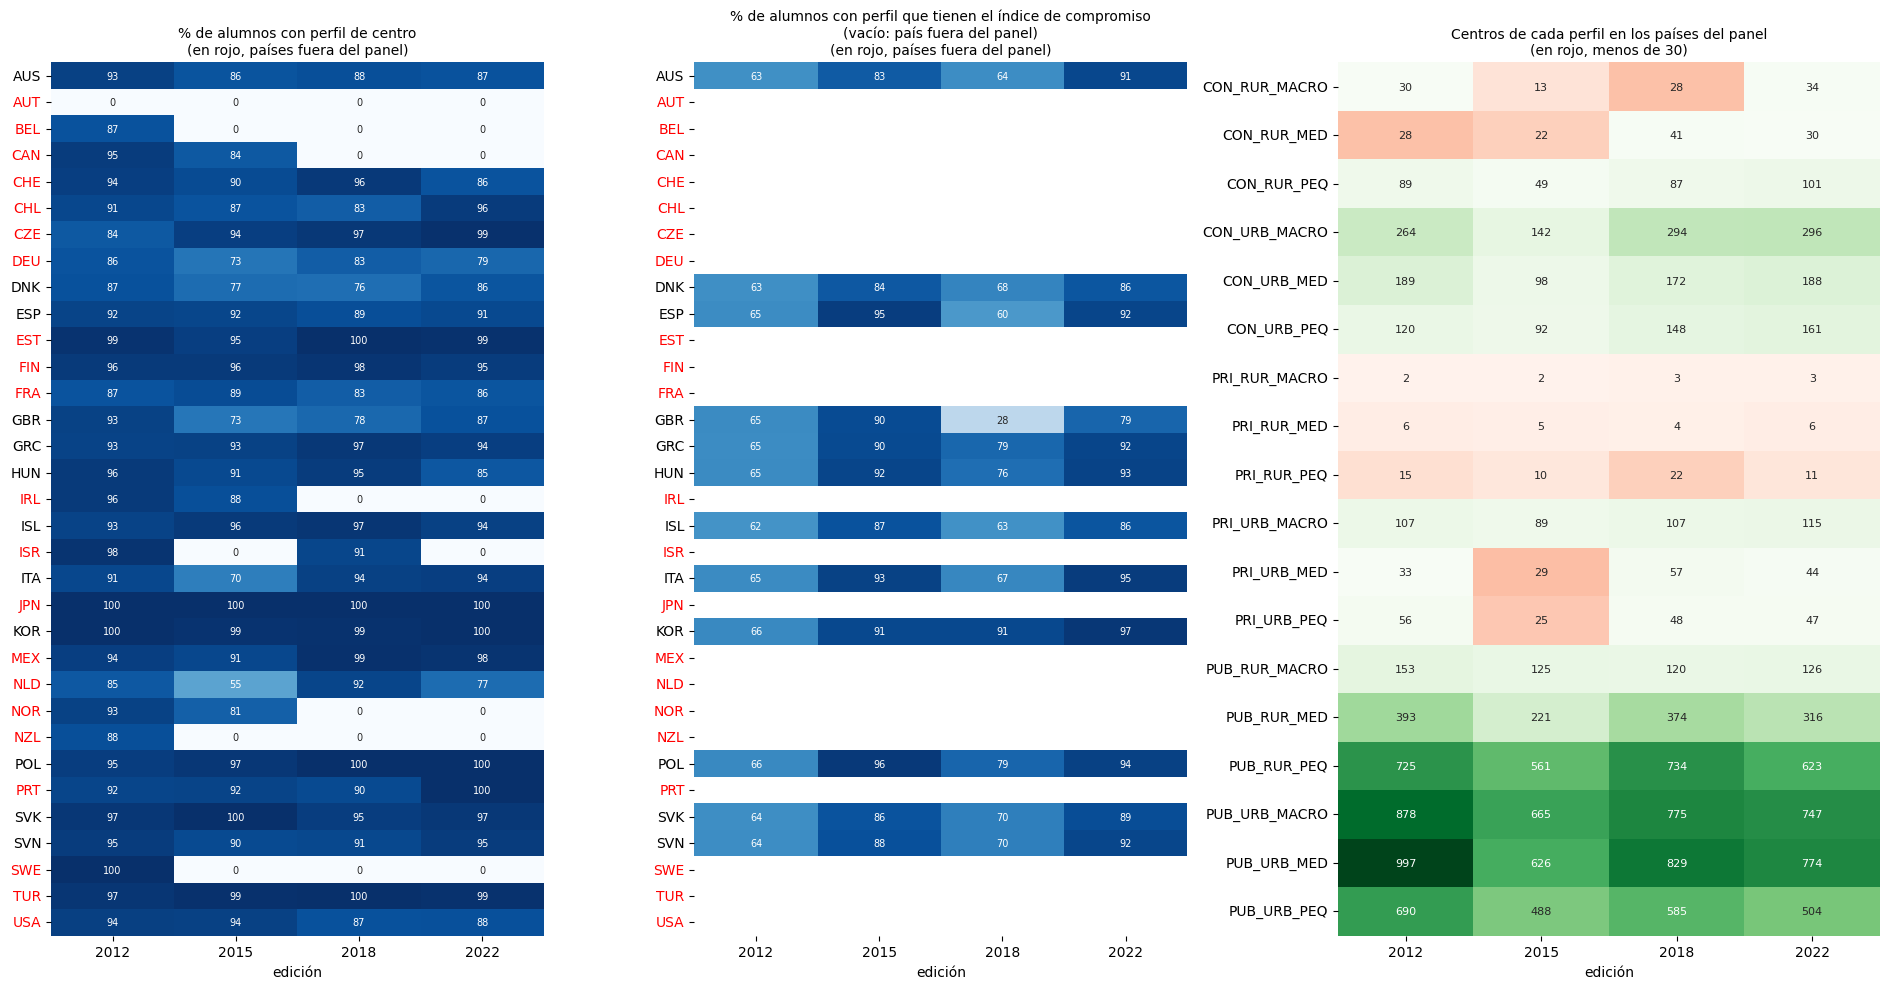

Países fuera del panel (21):
  sin ningún alumno con perfil en alguna edición (8): {'AUT': [2012, 2015, 2018, 2022], 'BEL': [2015, 2018, 2022], 'CAN': [2018, 2022], 'IRL': [2018, 2022], 'ISR': [2015, 2022], 'NOR': [2018, 2022], 'NZL': [2015, 2018, 2022], 'SWE': [2015, 2018, 2022]}
  con perfil en todas las ediciones, pero sin horas de deberes en 2018 (13; 01_EDA_indice_de_compromiso_competencia, sección 5.1): ['CHE', 'CHL', 'CZE', 'DEU', 'EST', 'FIN', 'FRA', 'JPN', 'MEX', 'NLD', 'PRT', 'TUR', 'USA']
% de alumnos con perfil en los países del panel: de 70 a 100
% de alumnos con perfil que tienen el índice de compromiso en el panel, por edición (mínimo y máximo):
year         2012       2015       2018       2022
min     62.099754  83.350627  28.080733  79.347443
idxmin        ISL        AUS        GBR        GBR
max     65.756881  96.132597  90.690599  97.195538
idxmax        POL        POL        KOR        KOR
Perfiles con al menos 30 centros en todas las ediciones: 11 de 18
Perfiles c

In [2]:
alumnos_por_pais = pd.concat([pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, edicion)[0], columns=['CNT']).astype(str).assign(year=edicion)
                              for edicion in EDICIONES])
con_perfil = pd.concat([pd.read_parquet(os.path.join(RUTA_INTERMEDIOS, 'estratos_fijos', f'pisa{edicion}_estratos_fijos.parquet'), columns=['CNT']).astype(str).assign(year=edicion)
                        for edicion in EDICIONES])
porcentaje_con_perfil = (100 * con_perfil.groupby(['CNT', 'year']).size() / alumnos_por_pais.groupby(['CNT', 'year']).size()).fillna(0).unstack('year')
paises_analisis = set(datos['CNT'])
panel = sorted(paises_analisis)

# % de alumnos con perfil que tienen el índice de compromiso (los tres componentes), por país-edición del panel
porcentaje_con_indice = (datos.groupby(['CNT', 'year'])['Indice_Compromiso_Competencia'].apply(lambda serie: 100 * serie.notna().mean())
                         .unstack('year').reindex(index=porcentaje_con_perfil.index, columns=EDICIONES))

centros_perfil = datos.groupby(['perfil', 'year'])['centro'].nunique().unstack('year').reindex(columns=EDICIONES).fillna(0).astype(int)
fig, ejes = plt.subplots(1, 3, figsize=(19, 10), gridspec_kw={'width_ratios': [1, 1, 1.1]})
for eje, tabla, titulo in zip(ejes[:2], [porcentaje_con_perfil, porcentaje_con_indice],
                              ['% de alumnos con perfil de centro', '% de alumnos con perfil que tienen el índice de compromiso\n(vacío: país fuera del panel)']):
    sns.heatmap(tabla, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar=False, ax=eje, annot_kws={'fontsize': 7})
    for etiqueta in eje.get_yticklabels():
        etiqueta.set_color('black' if etiqueta.get_text() in paises_analisis else 'red')
    eje.set_title(f'{titulo}\n(en rojo, países fuera del panel)', fontsize=10)
sns.heatmap(centros_perfil, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ejes[2], annot_kws={'fontsize': 8},
            mask=centros_perfil < MINIMO_CENTROS)
sns.heatmap(centros_perfil, annot=True, fmt='d', cmap='Reds', cbar=False, ax=ejes[2], annot_kws={'fontsize': 8},
            mask=centros_perfil >= MINIMO_CENTROS, vmin=0, vmax=4 * MINIMO_CENTROS)
ejes[2].set_title(f'Centros de cada perfil en los países del panel\n(en rojo, menos de {MINIMO_CENTROS})', fontsize=10)
for eje in ejes:
    eje.set_xlabel('edición')
    eje.set_ylabel('')
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_universo.png', dpi=300, bbox_inches='tight')
plt.show()

fuera = porcentaje_con_perfil[~porcentaje_con_perfil.index.isin(paises_analisis)]
sin_perfil = {pais: [edicion for edicion in EDICIONES if fila[edicion] == 0] for pais, fila in fuera.iterrows() if (fila == 0).any()}
sin_deberes = sorted(pais for pais in fuera.index if pais not in sin_perfil)
print(f'Países fuera del panel ({len(fuera)}):')
print(f'  sin ningún alumno con perfil en alguna edición ({len(sin_perfil)}):', sin_perfil)
print(f'  con perfil en todas las ediciones, pero sin horas de deberes en 2018 ({len(sin_deberes)}; 01_EDA_indice_de_compromiso_competencia, sección 5.1):', sin_deberes)
print(f'% de alumnos con perfil en los países del panel: de {porcentaje_con_perfil.loc[panel].min().min():.0f} a {porcentaje_con_perfil.loc[panel].max().max():.0f}')
print('% de alumnos con perfil que tienen el índice de compromiso en el panel, por edición (mínimo y máximo):')
print(porcentaje_con_indice.loc[panel].agg(['min', 'idxmin', 'max', 'idxmax']))
pocos = centros_perfil[(centros_perfil < MINIMO_CENTROS).any(axis=1)]
print(f'Perfiles con al menos {MINIMO_CENTROS} centros en todas las ediciones: {len(centros_perfil) - len(pocos)} de {len(centros_perfil)}')
print(f'Perfiles con menos de {MINIMO_CENTROS} centros en alguna edición:')
print(pocos.assign(ediciones_por_debajo=(pocos < MINIMO_CENTROS).sum(axis=1)))

**Qué se ve.**

* Entran 408.999 alumnos de 12 países (AUS, DNK, ESP, GBR, GRC, HUN, ISL, ITA, KOR, POL, SVK y SVN): de 78.136 (2015) a 115.762 (2012) por edición, en 3.262 a 4.775 centros. En estos países tienen perfil entre el 70 % y el 100 % de los alumnos.
* **21 países quedan fuera**:
  * 8 porque en alguna edición ningún alumno tiene perfil (PISA no publica la titularidad, la ubicación o el tamaño de sus centros): Austria en todas las ediciones; Bélgica, Nueva Zelanda y Suecia desde 2015; Canadá, Irlanda y Noruega en 2018 y 2022, e Israel en 2015 y 2022;
  * 13 porque, aun con perfil en las cuatro ediciones, no tienen horas de deberes en 2018 (no aplicaron el cuestionario opcional de ese año): CHE, CHL, CZE, DEU, EST, FIN, FRA, JPN, MEX, NLD, PRT, TUR y USA.
* **Índice de compromiso en el panel**: en 2012 lo tiene entre el 62 % y el 66 % de los alumnos de cada país (la pregunta de deberes estaba en una forma rotada del cuestionario); en 2018, entre el 28 % de Reino Unido y el 91 % de Corea. Reino Unido aporta a 2018 una submuestra pequeña.
* **Perfiles pequeños**: 11 de los 18 perfiles tienen al menos 30 centros en todas las ediciones. Los tres privados rurales no llegan en ninguna: grande (`PRI_RUR_MACRO`, de 2 a 3 centros), mediano (`PRI_RUR_MED`, de 4 a 6) y pequeño (`PRI_RUR_PEQ`, de 10 a 22). Los concertados rurales grande y mediano quedan por debajo en dos ediciones (`CON_RUR_MACRO`, 13 en 2015 y 28 en 2018; `CON_RUR_MED`, 28 en 2012 y 22 en 2015), y los privados urbanos mediano y pequeño solo en 2015 (29 y 25), la edición con menos alumnos.

## 2. Cómo se mide el compromiso en cada edición

El índice de compromiso y competencia (`01_EDA_indice_de_compromiso_competencia`) resume tres comportamientos con el mismo peso: las horas de deberes, el absentismo y la impuntualidad. Las horas no entran tal cual: se dividen en terciles dentro de cada edición y puntúa 1 el tercil central y 0 los otros dos (U invertida). La estandarización y el reescalado se calculan con las cuatro ediciones juntas y con `SENWT`, así que un cambio de la media entre ediciones es un cambio de comportamiento declarado, salvo en lo que cambie la pregunta de deberes. Solo lo tienen los alumnos con los tres componentes.

**Horas de deberes** (del mismo notebook, en horas al día y con un máximo de 4,5). La pregunta cambia en cada edición, según los codebooks de PISA:

* **2012**: horas a la semana de las preguntas `ST57Q01`, `ST57Q02` y `ST57Q05`, divididas entre 5.
* **2015**: horas a la semana de «aprendizaje adicional» en ciencias, matemáticas y lengua (`ST071Q01NA` a `ST071Q03NA`), divididas entre 5.
* **2018**: cuánto estudió el alumno al salir del colegio el último día que fue a clase (`EC159`), de un cuestionario opcional.
* **2022**: tiempo total de deberes al día, en seis tramos (`ST296Q04JA`, de «hasta 30 minutos» a «más de 4 horas»), convertidos al punto medio de cada tramo.

**Absentismo e impuntualidad**: la OCDE publica `SKIPPING` (ha faltado un día entero o se ha saltado alguna clase en las dos últimas semanas) y `TARDYSD` (ha llegado tarde: nunca, una o dos veces, tres o más) solo en 2022, pero sus ítems están en las cuatro ediciones con la misma escala. `construir_skipping` y `construir_tardysd` (`src/tabla_alumno.py`) aplican la regla de la OCDE en todas las ediciones.

Se comprueba que en 2022 dan lo mismo que los índices oficiales y que todo alumno con índice tiene los tres componentes, y se describe cada componente y el índice por edición (ponderado con `SENWT`).

In [3]:
oficiales = pd.read_parquet(rutas_datos_anuales(RUTA_RAW_BASE, 2022)[0], columns=CLAVES_ALUMNO + ['SKIPPING', 'TARDYSD']).astype({clave: str for clave in CLAVES_ALUMNO})
comparacion = datos[datos['year'] == 2022].merge(oficiales, on=CLAVES_ALUMNO, suffixes=('', '_ocde'), validate='one_to_one')
for indice in ['SKIPPING', 'TARDYSD']:
    ambos = comparacion[[indice, f'{indice}_ocde']].dropna()
    print(f"{indice} en 2022: igual al oficial en el {100 * (ambos[indice] == ambos[f'{indice}_ocde']).mean():.2f} % de {len(ambos)} alumnos; "
          f"vacío en {comparacion[indice].isna().sum()} alumnos (el oficial, en {comparacion[f'{indice}_ocde'].isna().sum()})")
con_indice = datos['Indice_Compromiso_Competencia'].notna()
print('Alumnos con índice y sin absentismo o impuntualidad:', (con_indice & datos[['SKIPPING', 'TARDYSD']].isna().any(axis=1)).sum(),
      '| con índice y sin horas de deberes:', (con_indice & datos['tiempo_deberes_totales_diarios'].isna()).sum())

descripcion = {}
for edicion, grupo in datos.groupby('year'):
    deberes_alumno = grupo['tiempo_deberes_totales_diarios']
    descripcion[edicion] = {
        'horas de deberes al día (media)': media_ponderada(deberes_alumno, grupo['SENWT']),
        '% con 0 horas': 100 * media_ponderada((deberes_alumno == 0).where(deberes_alumno.notna()).astype(float), grupo['SENWT']),
        '% con 4,5 horas (máximo)': 100 * media_ponderada((deberes_alumno >= 4.5).where(deberes_alumno.notna()).astype(float), grupo['SENWT']),
        '% con absentismo': 100 * media_ponderada(grupo['SKIPPING'], grupo['SENWT']),
        '% que llega tarde alguna vez': 100 * media_ponderada((grupo['TARDYSD'] >= 1).where(grupo['TARDYSD'].notna()).astype(float), grupo['SENWT']),
        '% que llega tarde tres o más veces': 100 * media_ponderada((grupo['TARDYSD'] == 2).where(grupo['TARDYSD'].notna()).astype(float), grupo['SENWT']),
        '% en el tercil central de deberes': 100 * media_ponderada(grupo['deberes_en_u'], grupo['SENWT']),
        '% con índice de compromiso': 100 * grupo['Indice_Compromiso_Competencia'].notna().mean(),
        'índice de compromiso (media)': media_ponderada(grupo['Indice_Compromiso_Competencia'], grupo['SENWT']),
    }
pd.DataFrame(descripcion).round(2)

SKIPPING en 2022: igual al oficial en el 100.00 % de 100655 alumnos; vacío en 4423 alumnos (el oficial, en 4423)
TARDYSD en 2022: igual al oficial en el 100.00 % de 100209 alumnos; vacío en 4869 alumnos (el oficial, en 4869)
Alumnos con índice y sin absentismo o impuntualidad: 0 | con índice y sin horas de deberes: 0


,2012,2015,2018,2022
horas de deberes al día (media),1.41,2.09,1.87,1.58
% con 0 horas,5.15,2.21,17.39,0.00
"% con 4,5 horas (máximo)",4.31,11.55,10.49,6.43
% con absentismo,27.99,37.10,35.01,34.81
% que llega tarde alguna vez,34.68,41.82,45.56,44.01
% que llega tarde tres o más veces,10.17,14.40,17.60,16.48
% en el tercil central de deberes,35.96,34.46,29.64,23.18
% con índice de compromiso,64.50,89.09,64.03,90.56
índice de compromiso (media),0.20,0.01,-0.06,-0.12


**Qué se ve.**

* **La regla de la OCDE se reproduce**: en 2022, el absentismo y la impuntualidad construidos coinciden con los oficiales en el 100 % de los alumnos y tienen los mismos vacíos.
* **Todo alumno con índice tiene los tres componentes**: lo tienen el 64,50 % en 2012, el 89,09 % en 2015, el 64,03 % en 2018 y el 90,56 % en 2022. En 2012 y 2018 los huecos vienen de las horas de deberes.
* **Horas de deberes**: la media va de 1,41 horas al día (2012) a 2,09 (2015), pero buena parte de la diferencia es de la pregunta. En 2018 el 17,39 % dice 0 horas (el último día no estudió), mientras que en 2022 nadie puede decir 0 (el primer tramo es «hasta 30 minutos»); el máximo de 4,5 horas lo alcanzan del 4,31 % (2012) al 11,55 % (2015) de los alumnos.
* **El tercil central no reúne a un tercio de los alumnos en todas las ediciones**: el 35,96 % en 2012, el 34,46 % en 2015, el 29,64 % en 2018 y el 23,18 % en 2022. Las horas toman pocos valores y los empates caen enteros en un tercil; en 2022, con seis tramos, es donde más se nota.
* **Absentismo e impuntualidad**: entre el 27,99 % y el 37,10 % de los alumnos ha faltado un día o a alguna clase en las dos últimas semanas, y entre el 34,68 % y el 45,56 % ha llegado tarde alguna vez (entre el 10,17 % y el 17,60 %, tres o más veces). La pregunta es la misma en todas las ediciones.
* **El índice baja a lo largo de la década**: de 0,20 en 2012 a 0,01, −0,06 y −0,12. Según `01_EDA_indice_de_compromiso_competencia` (sección 5.7.4), la caída de 2012 a 2015 viene de la asistencia y la de después, sobre todo de los deberes, porque el tercil central se hace más pequeño.

Por eso la evolución del nivel del índice entre ediciones es menos fiable en la parte de deberes, y la comprobación con los tres componentes por separado (`deberes_en_u`, `SKIPPING` y `TARDYSD`) permite ver si los resultados dependen de ella.

## 3. Alumnos sin dato y preguntas que no se hicieron

Para cada variable, el % de alumnos sin dato en cada edición (sin ponderar) y cuántos países-edición no hicieron la pregunta (`paises_edicion_sin_variable`: la variable falta en todos sus alumnos), con la lista de esos países-edición. Después, los países-edición en los que la dotación del centro falta a más del 10 % de los alumnos.

In [4]:
sin_pregunta = paises_edicion_sin_variable(datos, VARIABLES)
pais_edicion = pd.Series(list(zip(datos['CNT'], datos['year'])), index=datos.index)
resumen_nulos = datos[VARIABLES].isna().groupby(datos['year']).mean().mul(100).T
resumen_nulos.columns = [f'% sin dato {edicion}' for edicion in resumen_nulos.columns]
resumen_nulos['países-edición sin la pregunta'] = [len(sin_pregunta[variable]) for variable in VARIABLES]
display(resumen_nulos.round(1))
for variable in VARIABLES:
    if sin_pregunta[variable]:
        print(f'{variable}:', ', '.join(f'{pais} {edicion}' for pais, edicion in sorted(sin_pregunta[variable], key=lambda par: (par[1], par[0]))))
print('% de alumnos sin dotación del centro, por país-edición (los que pasan del 10 %):')
print(datos.groupby(['CNT', 'year'])['dotacion_centro'].apply(lambda serie: 100 * serie.isna().mean()).loc[lambda porcentaje: porcentaje > 10].round(1).to_dict())

,% sin dato 2012,% sin dato 2015,% sin dato 2018,% sin dato 2022,países-edición sin la pregunta
Indice_Compromiso_Competencia,35.5,10.9,36.0,9.4,0
recursos_estudio,1.6,2.3,2.9,13.3,0
HISEI_TREND,2.8,6.8,7.4,10.2,0
PAREDINT_TREND,3.6,3.4,4.2,4.8,0
riqueza_hogar,1.7,4.6,6.7,3.9,0
libros,1.8,2.0,2.9,3.3,0
sexo_femenino,0.0,0.0,0.0,0.0,0
inmigrante,2.6,3.1,4.0,5.4,0
composicion_social_centro,0.0,0.2,0.5,0.3,0
dotacion_centro,8.5,4.7,4.6,9.8,0


escasez_centro: KOR 2022, SVK 2022
% de alumnos sin dotación del centro, por país-edición (los que pasan del 10 %):
{('AUS', 2022): 19.3, ('DNK', 2022): 11.9, ('ESP', 2012): 13.9, ('GBR', 2018): 10.8, ('GBR', 2022): 25.2, ('ISL', 2012): 12.4, ('ISL', 2022): 19.9, ('SVK', 2012): 13.2}


**Qué se ve.**

* **Índice de compromiso** (y su componente de deberes, `deberes_en_u`): falta al 35,5 % de los alumnos en 2012, al 10,9 % en 2015, al 36,0 % en 2018 y al 9,4 % en 2022, por las horas de deberes (sección 2). Todos los países del panel hicieron las tres preguntas.
* **Absentismo e impuntualidad por separado**: faltan al 0,8-4,6 % de los alumnos, salvo en 2018 (17,2 % y 17,6 %).
* **Recursos de estudio**: faltan al 1,6-2,9 % hasta 2018 y al 13,3 % en 2022, por las preguntas de tipos de libros (`01_EDA_recursos_alumno`).
* **Controles del alumno**: la ocupación de los padres falta al 2,8-10,2 % de los alumnos, la riqueza del hogar al 1,7-6,7 % y la inmigración al 2,6-5,4 %; el resto, como mucho al 4,8 %. En el panel todos los países preguntan por la inmigración.
* **Controles del centro**: la composición social y el `ESCS` medio del centro faltan como mucho al 0,5 % de los alumnos. La dotación del centro falta al 4,6-9,8 %, y a más del 10 % en ocho países-edición, sobre todo en 2022: Reino Unido (25,2 %), Islandia (19,9 %), Australia (19,3 %) y Dinamarca (11,9 %); además, España, Eslovaquia e Islandia en 2012 (13,9 %, 13,2 % y 12,4 %) y Reino Unido en 2018 (10,8 %). Por eso entra con un indicador de «sin dato».
* **Escasez del centro**: en 2012 sale de otras preguntas (`01_EDA_recursos_centro`, sección 9). No existe en Corea y Eslovaquia en 2022 (falta la escasez de personal); en el resto falta al 0,7-1,3 % de los alumnos hasta 2018, y en 2022, contando esos dos países, al 16,5 %.

## 4. ¿Son distintos los alumnos sin dato?

Si los alumnos sin dato son distintos, la relación que mida el modelo vale para los que contestaron, no para todos. Para cada variable y edición, en los países-edición que hicieron la pregunta, se compara la nota de los alumnos sin dato con la de los que lo tienen, **relativa a la media de su país-edición** (media de sus valores plausibles, ponderada con `SENWT`), en las tres asignaturas. La diferencia (sin dato − con dato) queda vacía si hay menos de 100 alumnos sin dato.

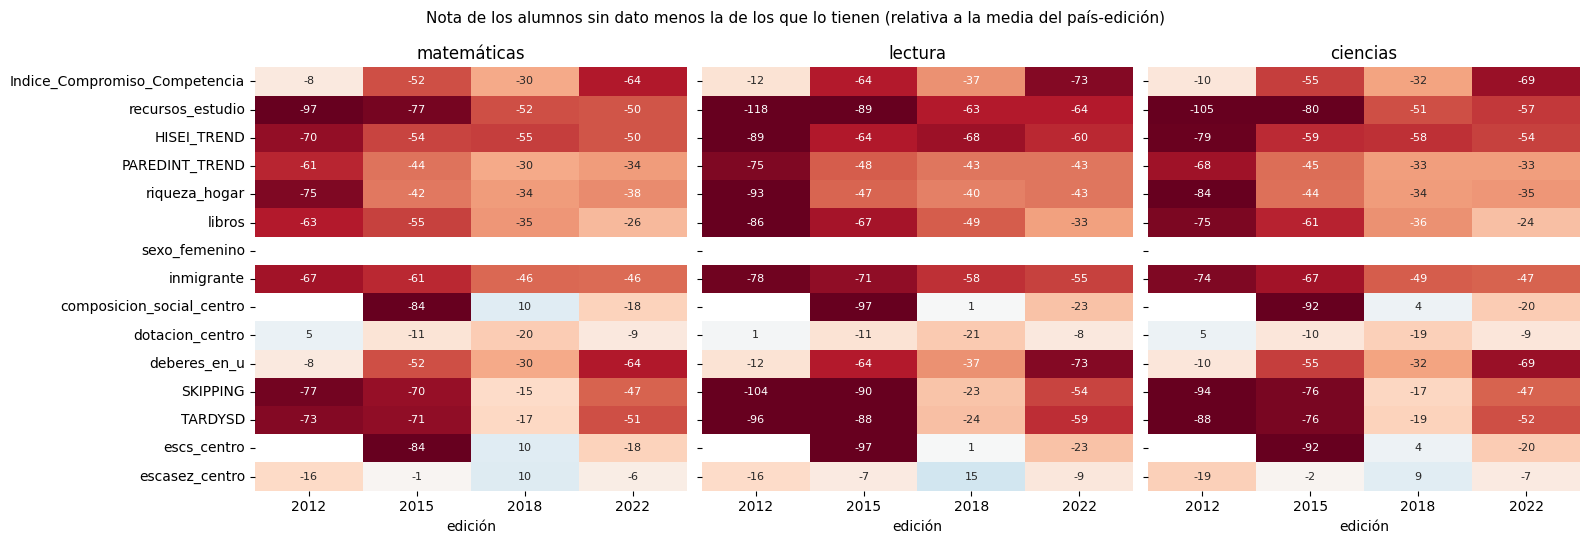

asignatura                    ciencias                   lectura                   matemáticas                  
edición                           2012  2015  2018  2022    2012  2015  2018  2022        2012  2015  2018  2022
variable                                                                                                        
Indice_Compromiso_Competencia     -9.7 -55.4 -32.2 -68.8   -11.8 -63.7 -36.5 -73.4        -8.1 -51.9 -30.2 -64.0
recursos_estudio                -105.3 -80.5 -51.3 -56.8  -117.6 -89.0 -63.4 -63.5       -96.6 -76.6 -51.8 -50.2
HISEI_TREND                      -79.1 -59.5 -58.5 -54.4   -88.6 -64.2 -68.4 -60.4       -70.2 -54.1 -55.4 -50.4
PAREDINT_TREND                   -68.0 -44.8 -33.2 -33.2   -75.0 -48.2 -43.0 -42.6       -61.0 -43.7 -30.2 -34.3
riqueza_hogar                    -84.3 -43.8 -33.9 -35.3   -93.3 -46.6 -40.1 -42.9       -74.6 -42.3 -34.0 -37.7
libros                           -75.0 -61.3 -36.4 -24.3   -86.3 -66.6 -48.6 -32.6       -63.3 -54.6 -35.4 -26.1
sexo_femenino                      NaN   NaN   NaN   NaN     NaN   NaN   NaN   NaN         NaN   NaN   NaN   NaN
inmigrante                       -74.4 -67.1 -48.6 -46.9   -77.9 -71.1 -58.3 -54.8       -67.2 -60.6 -46.2 -45.5
composicion_social_centro          NaN -92.0   4.3 -20.3     NaN -97.3   0.6 -23.4         NaN -83.7   9.9 -18.1
dotacion_centro                    4.5  -9.6 -18.9  -9.5     1.4 -11.5 -20.9  -8.4         5.2 -10.7 -20.4  -8.7
deberes_en_u                      -9.7 -55.4 -32.2 -68.8   -11.8 -63.7 -36.5 -73.4        -8.1 -51.9 -30.2 -64.0
SKIPPING                         -94.4 -76.0 -17.4 -46.9  -104.3 -89.9 -22.6 -54.0       -77.0 -70.0 -15.3 -47.2
TARDYSD                          -87.9 -76.1 -18.6 -51.7   -96.2 -87.8 -24.0 -59.0       -73.4 -70.8 -16.8 -51.4
escs_centro                        NaN -92.0   4.3 -20.3     NaN -97.3   0.6 -23.4         NaN -83.7   9.9 -18.1
escasez_centro                   -19.2  -2.1   8.9  -7.4   -15.6  -7.2  15.4  -8.8       -15.7  -1.4  10.4  -6.1

In [5]:
for asignatura, dominio in ASIGNATURAS.items():
    nota = datos[columnas_pv(dominio)].mean(axis=1)   # en 2012, media de sus 5 valores plausibles
    datos[f'nota_relativa_{asignatura}'] = centrar_en_grupos(datos.assign(nota=nota), ['nota'], ['pais_edicion'], peso_col='SENWT')['nota']


def diferencia_sin_dato(grupo, variable, asignatura='matemáticas'):
    """% de alumnos sin `variable`, cuántos son y su nota relativa media (con SENWT) menos la de los que la tienen
    (vacía con menos de `MINIMO_SIN_DATO` alumnos sin dato)."""
    hueco = grupo[variable].isna()
    nota = grupo[f'nota_relativa_{asignatura}']
    diferencia = (media_ponderada(nota[hueco], grupo['SENWT'][hueco]) - media_ponderada(nota[~hueco], grupo['SENWT'][~hueco])
                  if hueco.sum() >= MINIMO_SIN_DATO else np.nan)
    return pd.Series({'% sin dato': 100 * hueco.mean(), 'alumnos sin dato': hueco.sum(), 'diferencia': diferencia})


filas = []
for variable in VARIABLES:
    preguntada = datos[~pais_edicion.isin(sin_pregunta[variable])]
    for edicion, grupo in preguntada.groupby('year'):
        for asignatura in ASIGNATURAS:
            filas.append({'variable': variable, 'edición': edicion, 'asignatura': asignatura, **diferencia_sin_dato(grupo, variable, asignatura)})
huecos = pd.DataFrame(filas)
diferencias = huecos.pivot_table(index='variable', columns=['asignatura', 'edición'], values='diferencia').reindex(VARIABLES)

fig, ejes = plt.subplots(1, len(ASIGNATURAS), figsize=(16, 5.5), sharey=True)
for eje, asignatura in zip(ejes, ASIGNATURAS):
    sns.heatmap(diferencias[asignatura], annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-80, vmax=80, cbar=False, ax=eje, annot_kws={'fontsize': 8})
    eje.set_title(asignatura)
    eje.set_ylabel('')
fig.suptitle('Nota de los alumnos sin dato menos la de los que lo tienen (relativa a la media del país-edición)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_huecos.png', dpi=300, bbox_inches='tight')
plt.show()
diferencias.round(1)

**Qué se ve.**

* En casi todas las variables del alumno, los que no tienen dato sacan menos nota que los que lo tienen dentro de su país-edición, y la diferencia es algo mayor en lectura que en matemáticas y ciencias.
* **Índice de compromiso**: en 2012 la diferencia es pequeña (−8,1 puntos en matemáticas), porque el hueco viene de la rotación del cuestionario; en 2015, 2018 y 2022 es de −51,9, −30,2 y −64,0 puntos.
* **Absentismo e impuntualidad por separado**: entre −70,0 y −77,0 puntos en matemáticas en 2012 y 2015 y entre −47,2 y −51,4 en 2022; en 2018, donde faltan a más alumnos, solo entre −15,3 y −16,8.
* **Recursos de estudio**: de −96,6 puntos en matemáticas (2012) a −50,2 (2022), aunque hasta 2018 faltan a menos del 3 % de los alumnos.
* **Controles del alumno**: entre −26,1 y −74,6 puntos en matemáticas.
* **Controles del centro**: los alumnos de centros sin dotación apenas se distinguen (de −20,4 a 5,2 puntos en matemáticas), y los de centros sin escasez tampoco, salvo en 2012, cuando son el 0,7 % (de −15,7 a 10,4). La composición social y el `ESCS` medio faltan a tan pocos alumnos que sus diferencias (de −83,7 a 9,9 puntos; en 2012, menos de 100 alumnos sin dato) apenas pesan.

**Consecuencia para el modelo**: la relación que se mida con cada variable de interés vale para los alumnos que contestaron, que sacan más nota que la media de su país. No se imputa, porque la variable de interés imputada dependería del modelo de imputación; este límite se cuenta al presentar los resultados. En los controles del centro el indicador de «sin dato» basta, porque los alumnos sin dato se parecen a los demás.

## 5. Alumnos sin dato por perfil de centro

Si unos perfiles pierden más alumnos sin dato que otros, o alumnos más flojos, la comparación entre perfiles se mezcla con quién contesta. Se repite la comparación anterior en matemáticas para las variables de interés, por cada eje del perfil (titularidad, ubicación y tamaño; tablas) y por perfil (gráfico).

**Indice_Compromiso_Competencia**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                   diferencia                  
year                    2012  2015  2018  2022       2012  2015  2018  2022
eje         grupo                                                          
titularidad CON         34.8   9.1  31.9   9.9       -5.4 -59.6 -24.5 -45.0
            PRI         34.9   6.0  31.8   6.5       -2.8 -50.7 -33.8 -45.8
            PUB         35.7  11.5  37.3   9.5       -8.6 -49.5 -30.0 -70.8
ubicacion   RUR         35.9  11.3  40.6  11.1       -9.3 -45.8 -27.5 -61.0
            URB         35.4  10.8  34.2   8.9       -7.3 -54.1 -30.0 -63.2
tamaño      MACRO       34.9   9.8  38.9   9.9       -6.7 -60.2 -30.0 -56.7
            MED         35.9  11.4  35.9   8.5       -8.1 -49.7 -30.8 -65.1
            PEQ         35.7  11.6  32.7  10.1       -8.7 -47.3 -29.3 -67.9

**recursos_estudio**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil

% sin dato                 diferencia                  
year                    2012 2015 2018  2022       2012  2015  2018  2022
eje         grupo                                                        
titularidad CON          1.3  1.3  3.2  12.9     -103.3 -78.6 -32.3 -40.5
            PRI          0.9  1.3  5.0  10.0        NaN   NaN -24.7 -45.2
            PUB          1.6  2.6  2.6  13.6      -93.4 -74.5 -63.4 -52.7
ubicacion   RUR          1.8  2.5  2.8  15.5      -96.8 -80.3 -69.9 -48.8
            URB          1.5  2.3  2.9  12.5      -95.0 -74.4 -44.9 -48.3
tamaño      MACRO        1.4  2.4  3.6  13.0     -115.4 -75.6 -24.5 -49.4
            MED          1.7  2.5  2.7  13.0      -97.1 -72.6 -57.2 -45.4
            PEQ          1.6  2.2  2.2  13.9      -82.3 -80.5 -83.1 -54.2

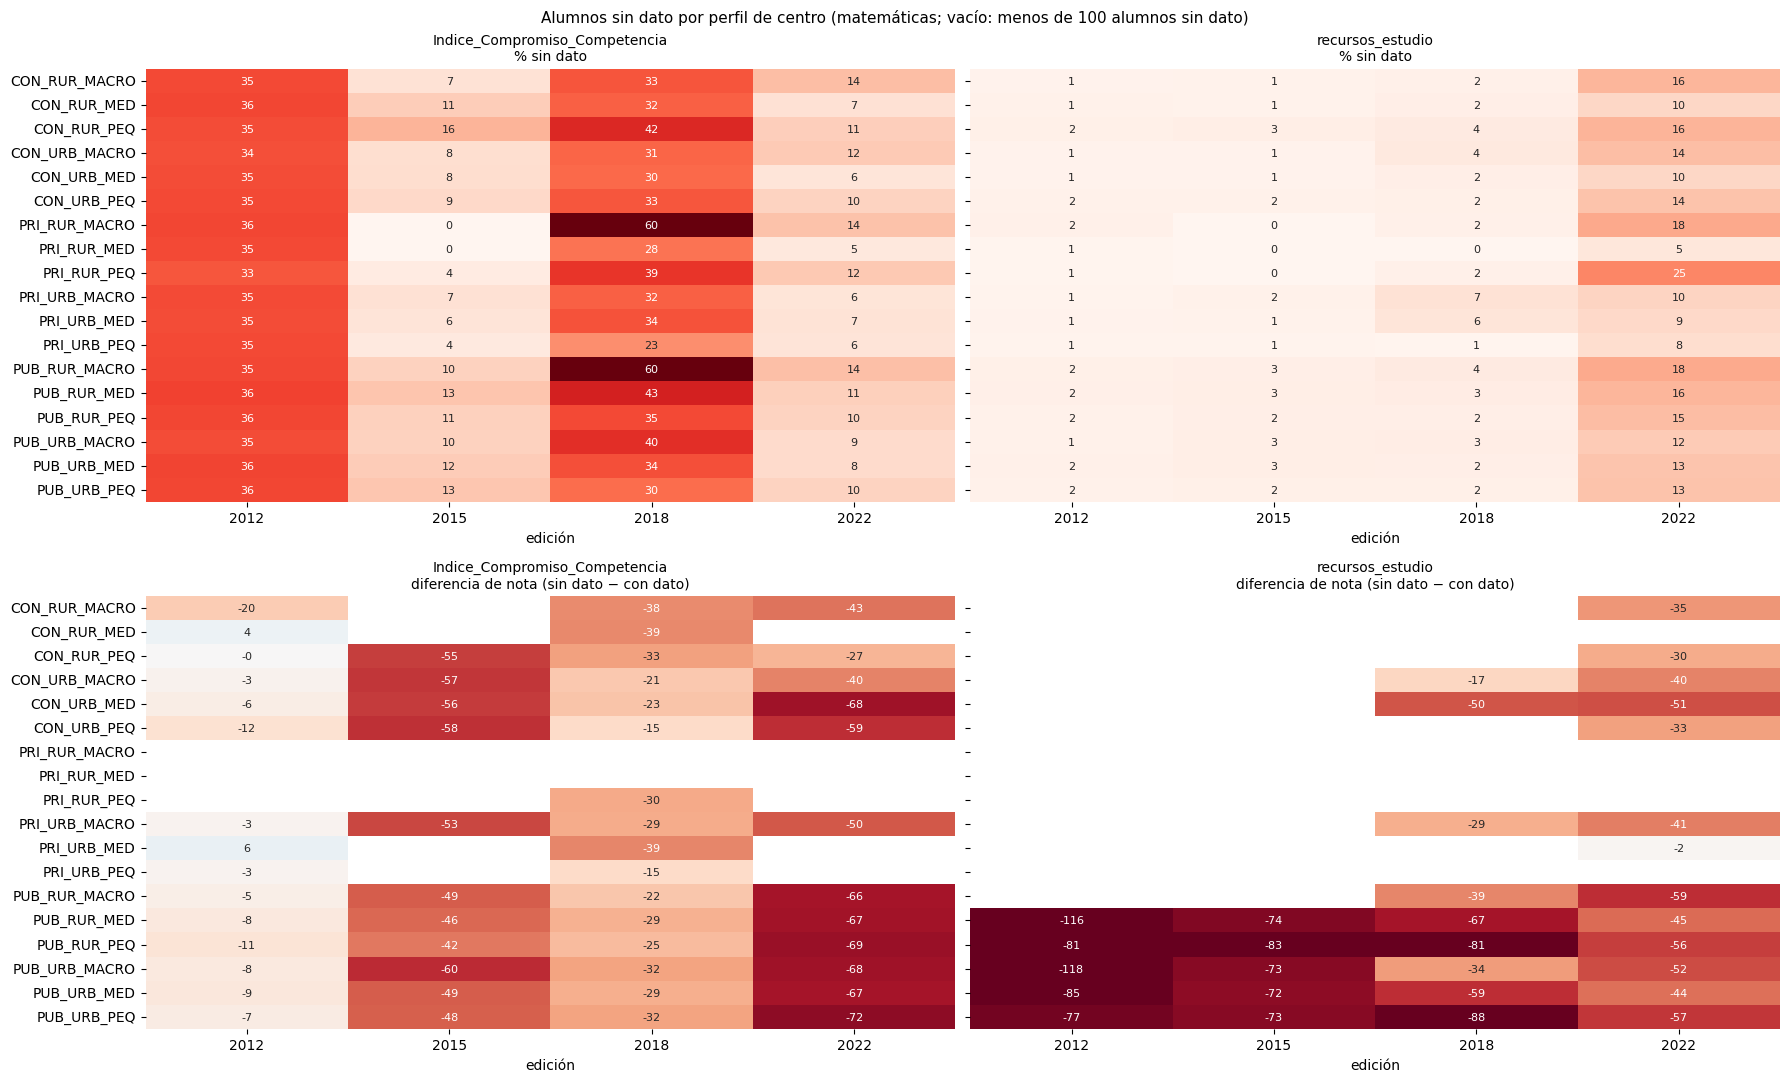

In [6]:
def tabla_huecos(datos_grupo, columna_grupo, variable):
    """% sin dato y diferencia de nota en matemáticas (sin dato − con dato) de cada grupo, por edición."""
    resumen = datos_grupo.groupby([columna_grupo, 'year']).apply(diferencia_sin_dato, variable, include_groups=False)
    return resumen[['% sin dato', 'diferencia']].unstack('year')


por_perfil = {}
for variable in DE_INTERES:
    preguntada = datos[~pais_edicion.isin(sin_pregunta[variable])]
    display(Markdown(f'**{variable}**: % sin dato y diferencia de nota en matemáticas (sin dato − con dato), por eje del perfil'))
    display(pd.concat({eje: tabla_huecos(preguntada, eje, variable) for eje in EJES_PERFIL}, names=['eje', 'grupo']).round(1))
    por_perfil[variable] = tabla_huecos(preguntada, 'perfil', variable)

fig, ejes = plt.subplots(2, len(DE_INTERES), figsize=(18, 11), sharey=True)
for columna_eje, variable in enumerate(DE_INTERES):
    sns.heatmap(por_perfil[variable]['% sin dato'], annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=60, cbar=False, ax=ejes[0, columna_eje], annot_kws={'fontsize': 8})
    sns.heatmap(por_perfil[variable]['diferencia'], annot=True, fmt='.0f', cmap='RdBu', center=0, vmin=-80, vmax=80, cbar=False, ax=ejes[1, columna_eje], annot_kws={'fontsize': 8})
    ejes[0, columna_eje].set_title(f'{variable}\n% sin dato', fontsize=10)
    ejes[1, columna_eje].set_title(f'{variable}\ndiferencia de nota (sin dato − con dato)', fontsize=10)
for eje in ejes.flat:
    eje.set_xlabel('edición')
    eje.set_ylabel('')
fig.suptitle('Alumnos sin dato por perfil de centro (matemáticas; vacío: menos de 100 alumnos sin dato)', fontsize=11)
plt.tight_layout()
fig.savefig(f'{RUTA_REPORTS}/01_variables_modelo_huecos_perfil.png', dpi=300, bbox_inches='tight')
plt.show()

**Qué se ve.**

* **El % de alumnos sin dato depende de la edición, más que del perfil.** En el índice de compromiso, entre grupos de un mismo eje va del 34,8 % al 35,9 % en 2012, del 6,0 % al 11,6 % en 2015, del 31,8 % al 40,6 % en 2018 y del 6,5 % al 11,1 % en 2022. En 2018 es donde más varía: faltan más en los centros rurales (40,6 %) que en los urbanos (34,2 %).
* **En 2022, los alumnos sin índice de compromiso de los centros públicos son más flojos que los de los concertados y privados**: sacan 70,8 puntos menos que los que lo tienen en los públicos, frente a 45,0 en los concertados y 45,8 en los privados. En los recursos de estudio la distancia es menor (52,7, 40,5 y 45,2).
* **El orden entre grupos no se mantiene en todas las ediciones**: en el índice de compromiso de 2015, los concertados pierden alumnos más flojos (−59,6) que los públicos (−49,5).
* **Muchas diferencias por perfil quedan vacías** (menos de 100 alumnos sin dato): en el índice de compromiso, las de los siete perfiles con menos de 30 centros en alguna edición (las de los privados rurales, en casi todas las ediciones); en los recursos de estudio, las de muchos perfiles hasta 2018, cuando faltan a pocos alumnos.

**Consecuencia para el modelo**: dentro de cada edición, todos los perfiles pierden una proporción parecida de alumnos, pero en 2022 los públicos pierden alumnos más flojos en el índice de compromiso, así que la comparación entre públicos y el resto de ese año se apoya en alumnos públicos más seleccionados. Es un límite que hay que contar.

## Hallazgos

* **Universo**: 408.999 alumnos con perfil de centro de los 12 países con índice de compromiso en las cuatro ediciones. De los 33 países, 8 quedan fuera porque PISA no publica en alguna edición los datos que definen el perfil y 13 porque no tienen horas de deberes en 2018.
* **Perfiles**: 11 de los 18 perfiles tienen al menos 30 centros en todas las ediciones. Los tres privados rurales no llegan en ninguna (como mucho 3, 6 y 22 centros) y sus resultados no serán representativos; los concertados rurales grande y mediano quedan por debajo en dos ediciones, y los privados urbanos mediano y pequeño solo en 2015.
* **Compromiso**: el índice existe exactamente para los alumnos con los tres componentes (64-91 % según la edición, por las horas de deberes). Su media baja de 0,20 en 2012 a −0,12 en 2022, pero desde 2015 la caída viene sobre todo de que el tercil central de deberes se hace más pequeño (del 35,96 % al 23,18 % de los alumnos), por los empates de la pregunta; la comprobación con los tres componentes por separado lo controla.
* **Controles del centro**: la dotación falta al 4,6-9,8 % de los alumnos (hasta el 25,2 % en Reino Unido 2022) y los alumnos sin dato se parecen a los demás, así que basta un indicador de «sin dato». La escasez existe en las cuatro ediciones (en 2012, con otras preguntas), salvo en Corea y Eslovaquia en 2022.
* **Huecos que no son al azar** en las variables del alumno: los alumnos sin dato sacan menos nota que la media de su país (en matemáticas, hasta 96,6 puntos menos en las variables de interés), salvo el índice de compromiso de 2012, que falta por la rotación del cuestionario (−8,1). Las relaciones que mida el modelo valen para los alumnos que contestaron.
* **Huecos por perfil**: el % sin dato apenas cambia con el perfil dentro de cada edición, pero en 2022 los alumnos sin índice de compromiso de los centros públicos son más flojos que los de los demás (70,8 puntos menos que los que lo tienen, frente a 45,0-45,8).